# Part 3 — Machine learning: predicting no-shows
**Goal:** flag risky bookings *before* the appointment.

**Models compared:** Logistic Regression, Decision Tree, Random Forest (plus a "predict nobody" dummy as a reference).

**Why recall?** Only ~1 in 5 bookings is a no-show, so a model that never predicts a no-show is already ~80 % *accurate* but useless. The cost that matters is **missing a real no-show**, so models are compared mainly on **recall** (share of real no-shows we catch), with precision / F1 / ROC-AUC alongside.

**Project rules followed here**
- every random seed is `42`
- quartiles / medians were computed on **all rows in Part 1**, before any split (this notebook asserts there is nothing left to impute)
- data is split **train 60 % / validation 20 % / test 20 %** (stratified). Models are compared and tuned using **train + validation only**; the **test set is used exactly once**, at the very end, to report the final score.

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve, classification_report)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
np.random.seed(SEED)
DATA, OUT = Path("../data"), Path("../outputs")
(OUT / "models").mkdir(parents=True, exist_ok=True)
(OUT / "figures").mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)

## 1. Load data and build the feature table

In [2]:
df = pd.read_csv(DATA / "Appointments_clean.csv", parse_dates=["scheduled_date", "appointment_date"])
df["appointment_weekday"] = df["appointment_date"].dt.dayofweek

NUMERIC = ["age", "lead_days", "lead_quartile", "previous_no_shows", "sms_received",
           "insurance_covered", "avg_temp_c", "appointment_weekday"]
CATEGORICAL = ["gender", "clinic", "specialty"]
TARGET = "no_show"

X, y = df[NUMERIC + CATEGORICAL], df[TARGET]
assert X.notna().all().all(), "missing values should already have been handled in Part 1"
print(f"{X.shape[0]:,} rows, {X.shape[1]} features | no-show rate {y.mean():.1%}")
X.head(3)

11,964 rows, 11 features | no-show rate 19.8%


/tmp/ipykernel_19237/3082515753.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["appointment_weekday"] = df["appointment_date"].dt.dayofweek


,age,lead_days,lead_quartile,previous_no_shows,sms_received,insurance_covered,avg_temp_c,appointment_weekday,gender,clinic,specialty
0,62,12,3,2,1,1,24.1,4,M,CareClick Indiranagar,Orthopedics
1,22,4,2,0,1,0,22.3,1,M,CareClick Indiranagar,Dental
2,22,10,3,0,1,0,27.4,5,M,CareClick Andheri,Pediatrics


## 2. Train / validation / test split (stratified, seed 42)

In [3]:
X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=SEED)
pd.DataFrame({"rows": [len(X_train), len(X_val), len(X_test)],
              "no_show_rate": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["train (60%)", "validation (20%)", "test (20%) - locked until the end"]).round(3)

,rows,no_show_rate
train (60%),7178,0.198
validation (20%),2393,0.198
test (20%) - locked until the end,2393,0.198


## 3. Compare three models on the **validation** set
All three use class weights to handle the 80 / 20 imbalance. Settings are deliberately modest (a fully-grown tree or forest simply memorises the training rows); tuning comes next.

In [4]:
def preprocessor(scale_numeric):
    return ColumnTransformer([
        ("num", StandardScaler() if scale_numeric else "passthrough", NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL)])

CANDIDATES = {
    "Logistic Regression": Pipeline([("prep", preprocessor(True)),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))]),
    "Decision Tree": Pipeline([("prep", preprocessor(False)),
        ("model", DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, class_weight="balanced", random_state=SEED))]),
    "Random Forest": Pipeline([("prep", preprocessor(False)),
        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced_subsample",
                                         n_jobs=-1, random_state=SEED))]),
}
dummy = Pipeline([("prep", preprocessor(False)), ("model", DummyClassifier(strategy="most_frequent"))])

def scores(model, X_, y_):
    pred, proba = model.predict(X_), model.predict_proba(X_)[:, 1]
    return {"accuracy": accuracy_score(y_, pred), "recall": recall_score(y_, pred),
            "precision": precision_score(y_, pred, zero_division=0), "f1": f1_score(y_, pred),
            "roc_auc": roc_auc_score(y_, proba)}

rows = {"Dummy (never predicts a no-show)": scores(dummy.fit(X_train, y_train), X_val, y_val)}
for name, model in CANDIDATES.items():
    rows[name] = scores(model.fit(X_train, y_train), X_val, y_val)
comparison = pd.DataFrame(rows).T.round(3)
comparison.to_csv(OUT / "model_comparison_validation.csv")
comparison

,accuracy,recall,precision,f1,roc_auc
Dummy (never predicts a no-show),0.802,0.000,0.000,0.000,0.500
Logistic Regression,0.674,0.615,0.328,0.428,0.714
Decision Tree,0.643,0.577,0.296,0.391,0.668
Random Forest,0.741,0.476,0.379,0.422,0.690


Note the dummy row: high accuracy, **zero recall** — which is exactly why accuracy is the wrong yardstick here.

Chosen model (highest validation recall): Logistic Regression


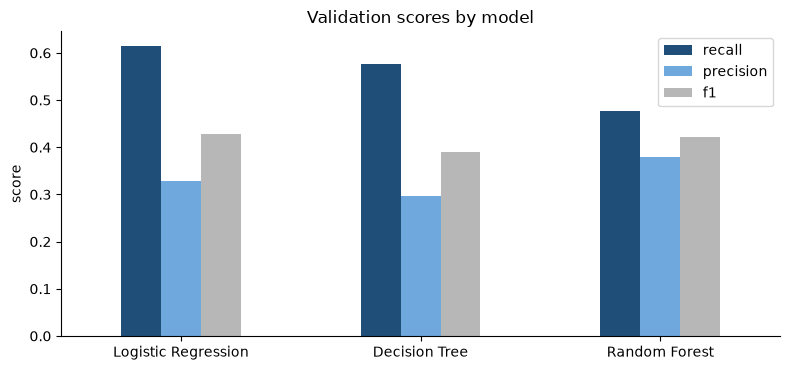

In [5]:
cand = comparison.drop(index="Dummy (never predicts a no-show)")
chosen_name = cand.sort_values(["recall", "roc_auc"], ascending=False).index[0]
print("Chosen model (highest validation recall):", chosen_name)

fig, ax = plt.subplots(figsize=(8, 3.8))
cand[["recall", "precision", "f1"]].plot.bar(ax=ax, color=["#1f4e79", "#6fa8dc", "#b7b7b7"], rot=0)
ax.set(title="Validation scores by model", ylabel="score")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "figures" / "03_model_comparison.png", dpi=130, bbox_inches="tight")

## 4. Tune the chosen model with `GridSearchCV`
- Cross-validation runs on the **training split only** (5 stratified folds, seed 42) — validation and test rows are never touched.
- Candidates are ranked by **recall**, but only among settings whose cross-validated **precision is at least 0.30**. Without a floor, recall alone would reward "flag everybody"; 0.30 means at least ~3 in 10 flagged bookings are real no-shows, so the front desk is not flooded with false alarms.

In [6]:
GRIDS = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10],
                            "model__class_weight": ["balanced", {0: 1, 1: 2}, {0: 1, 1: 3}]},
    "Decision Tree": {"model__max_depth": [3, 4, 5, 6, 8], "model__min_samples_leaf": [20, 50, 100],
                      "model__class_weight": ["balanced"]},
    "Random Forest": {"model__n_estimators": [200, 400], "model__max_depth": [6, 10, None],
                      "model__min_samples_leaf": [5, 10, 25], "model__class_weight": ["balanced_subsample"]},
}
PRECISION_FLOOR = 0.30

def best_recall_above_precision_floor(cv_results):
    prec, rec = np.asarray(cv_results["mean_test_precision"]), np.asarray(cv_results["mean_test_recall"])
    pool = np.where(prec >= PRECISION_FLOOR)[0]
    pool = pool if len(pool) else np.arange(len(prec))
    return int(pool[np.argmax(rec[pool])])

grid = GridSearchCV(
    estimator=clone(CANDIDATES[chosen_name]),
    param_grid=GRIDS[chosen_name],
    scoring={"recall": "recall", "precision": "precision", "f1": "f1", "roc_auc": "roc_auc"},
    refit=best_recall_above_precision_floor,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    n_jobs=-1,
)
grid.fit(X_train, y_train)

cv = pd.DataFrame(grid.cv_results_)
keep = [c for c in cv.columns if c.startswith("param_")] + ["mean_test_recall", "mean_test_precision", "mean_test_f1", "mean_test_roc_auc"]
cv = cv[keep].sort_values("mean_test_recall", ascending=False).round(3)
cv.to_csv(OUT / "gridsearch_results.csv", index=False)
print("Best parameters:", grid.best_params_)
print(f"{len(cv)} candidate settings x 5 folds searched")
cv.head(8)

Best parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'}
12 candidate settings x 5 folds searched


,param_model__C,param_model__class_weight,mean_test_recall,mean_test_precision,mean_test_f1,mean_test_roc_auc
3,0.10,balanced,0.611,0.333,0.431,0.710
6,1.00,balanced,0.610,0.332,0.430,0.710
9,10.00,balanced,0.610,0.332,0.430,0.709
0,0.01,balanced,0.604,0.334,0.430,0.710
8,1.00,"{0: 1, 1: 3}",0.484,0.395,0.435,0.710
11,10.00,"{0: 1, 1: 3}",0.483,0.395,0.434,0.710
5,0.10,"{0: 1, 1: 3}",0.483,0.396,0.435,0.710
2,0.01,"{0: 1, 1: 3}",0.467,0.400,0.431,0.710


### Did tuning help? (validation set — still not the test set)
A simple, well-regularised linear model usually has little left to gain from tuning, so a small change here is normal — the honest number is reported either way.

In [7]:
best_model = grid.best_estimator_
before = scores(CANDIDATES[chosen_name], X_val, y_val)
after = scores(best_model, X_val, y_val)
effect = pd.DataFrame({"before tuning": before, "after tuning": after}).T.round(3)
print(f"Tuning changed validation recall by {(after['recall'] - before['recall']) * 100:+.1f} points and "
      f"precision by {(after['precision'] - before['precision']) * 100:+.1f} points.")
effect

Tuning changed validation recall by +0.2 points and precision by -0.0 points.


,accuracy,recall,precision,f1,roc_auc
before tuning,0.674,0.615,0.328,0.428,0.714
after tuning,0.673,0.617,0.328,0.428,0.714


## 5. Final evaluation — the test set is used **once**
The tuned model is evaluated on the 20 % of bookings it has never seen and that played no part in model choice or tuning.

In [8]:
test_scores = scores(best_model, X_test, y_test)
pred_test, proba_test = best_model.predict(X_test), best_model.predict_proba(X_test)[:, 1]
tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
print(f"FINAL MODEL: {chosen_name} (tuned)")
print({k: round(v, 3) for k, v in test_scores.items()})
print(f"\nOf {tp + fn} real no-shows in the test set the model caught {tp} (recall {tp/(tp+fn):.1%}); "
      f"it raised {fp} false alarms among {tn + fp} patients who did show up.\n")
print(classification_report(y_test, pred_test, target_names=["showed up", "no-show"], digits=3))

json.dump({"model": chosen_name, "best_params": {k: str(v) for k, v in grid.best_params_.items()},
           "precision_floor_used_in_tuning": PRECISION_FLOOR,
           "validation_before_tuning": {k: round(v, 4) for k, v in before.items()},
           "validation_after_tuning": {k: round(v, 4) for k, v in after.items()},
           "test": {k: round(v, 4) for k, v in test_scores.items()},
           "test_confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
           "split_sizes": {"train": len(X_train), "validation": len(X_val), "test": len(X_test)},
           "seed": SEED}, open(OUT / "final_metrics.json", "w"), indent=2)

FINAL MODEL: Logistic Regression (tuned)
{'accuracy': 0.702, 'recall': 0.618, 'precision': 0.356, 'f1': 0.451, 'roc_auc': 0.732}

Of 474 real no-shows in the test set the model caught 293 (recall 61.8%); it raised 531 false alarms among 1919 patients who did show up.

              precision    recall  f1-score   support

   showed up      0.885     0.723     0.796      1919
     no-show      0.356     0.618     0.451       474

    accuracy                          0.702      2393
   macro avg      0.620     0.671     0.624      2393
weighted avg      0.780     0.702     0.728      2393



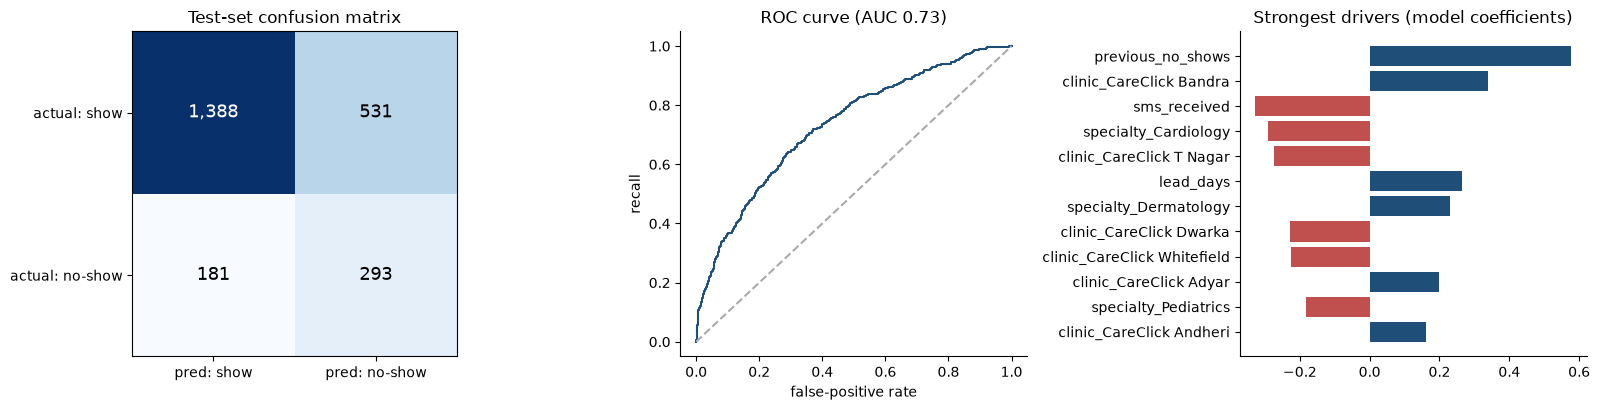

In [9]:
names = best_model.named_steps["prep"].get_feature_names_out()
est = best_model.named_steps["model"]
imp = pd.Series(est.coef_[0] if hasattr(est, "coef_") else est.feature_importances_, index=names)
imp.index = imp.index.str.replace("num__", "").str.replace("cat__", "")
top = imp.reindex(imp.abs().sort_values(ascending=False).index)[:12][::-1]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
cm = np.array([[tn, fp], [fn, tp]])
ax[0].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[0].text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=13)
ax[0].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["pred: show", "pred: no-show"], yticklabels=["actual: show", "actual: no-show"],
          title="Test-set confusion matrix")
fpr, tpr, _ = roc_curve(y_test, proba_test)
ax[1].plot(fpr, tpr, color="#1f4e79"); ax[1].plot([0, 1], [0, 1], "--", color="#aaa")
ax[1].set(title=f"ROC curve (AUC {test_scores['roc_auc']:.2f})", xlabel="false-positive rate", ylabel="recall")
ax[2].barh(top.index, top.values, color=["#c0504d" if v < 0 else "#1f4e79" for v in top.values])
ax[2].set(title="Strongest drivers (model coefficients)" if hasattr(est, "coef_") else "Top feature importances")
for a in ax[1:]:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "figures" / "03_final_model.png", dpi=130, bbox_inches="tight")

## 6. Score every booking and save the model
Each booking gets a **risk score** (predicted no-show probability) from a model that has *not* seen that row:
- train + validation rows → 5-fold **out-of-fold** predictions using the tuned settings (cross-validation inside train+validation only)
- test rows → the final tuned model, which never saw them

Bands use percentile cut-offs computed on **all rows**: **High** = top 15 %, **Medium** = next 25 %, **Low** = the rest.

In [10]:
oof = cross_val_predict(clone(best_model), X_trval, y_trval,
                        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
risk = pd.concat([pd.Series(oof, index=X_trval.index), pd.Series(proba_test, index=X_test.index)]).sort_index()

p60, p85 = risk.quantile([0.60, 0.85])
scores_df = pd.DataFrame({
    "appointment_id": df["appointment_id"], "clinic": df["clinic"], "appointment_date": df["appointment_date"].dt.date,
    "risk_score": risk.round(4).values,
    "risk_band": np.where(risk >= p85, "High", np.where(risk >= p60, "Medium", "Low")),
    "actual_no_show": y.values})
scores_df.to_csv(OUT / "risk_scores.csv", index=False)
joblib.dump(best_model, OUT / "models" / "best_model.joblib")

band = scores_df.groupby("risk_band").agg(bookings=("actual_no_show", "size"), no_show_rate=("actual_no_show", "mean")).reindex(["High", "Medium", "Low"])
band["no_show_rate"] = (band["no_show_rate"] * 100).round(1)
print(f"Cut-offs: Medium >= {p60:.3f}, High >= {p85:.3f}")
band

Cut-offs: Medium >= 0.480, High >= 0.648


,bookings,no_show_rate
risk_band,,
High,1795,46.2
Medium,2991,23.8
Low,7178,11.6


**Reading the table:** if the bands separate cleanly (High ≫ Medium ≫ Low), the front desk can spend its limited calls on the High band first. `outputs/risk_scores.csv` feeds Part 4.